# Import tariffs by country: Middle East first

**What rate of import duty does a typical product face entering each Middle East economy, and how does the region compare with the rest of the world?**

Source: WTO, ITC and UNCTAD, *World Tariff Profiles 2026*, summary table "All products" (152 economies). Measure: simple average of MFN applied tariff rates across all tariff lines, 2025 (2024 for 12 economies).

This notebook reads the processed tables written by `scripts/build_data.py`, recomputes the key figures from the tidy table, and asserts that they match.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
tidy = pd.read_csv("../data/processed/tariffs_tidy.csv")
me = pd.read_csv("../data/processed/middle_east.csv")
summ = pd.read_csv("../data/processed/region_summary.csv")
checks = pd.read_csv("../data/processed/source_checks.csv")
print(tidy.shape)
print(tidy.head().to_string(index=False))

(152, 15)
             economy country iso3      region      sub_region  wto_member  mfn_year  mfn_applied_avg  bound_avg  binding_coverage  rank_low_to_high  economies_higher  share_economies_lower_pct readings                            wto_profile_check
              Israel  Israel  ISR Middle East Levant and Iraq        True    2025.0              1.1       22.5              75.8               8.0             124.0                        5.3      two                                  not checked
              Jordan  Jordan  JOR Middle East Levant and Iraq        True    2025.0              4.0       16.2             100.0              24.0             108.0                       17.4      two                                  not checked
               Libya   Libya  LBY Middle East    North Africa       False    2025.0              4.5        NaN               NaN              28.0             104.0                       20.5      two confirmed value: profile labels another year
Ku

## 1. Data checks

In [2]:
assert len(tidy) == 152 and not tidy.economy.duplicated().any()
withv = tidy[tidy.mfn_applied_avg.notna()]
print("economies in table:", len(tidy))
print("with an applied average:", len(withv))
print("without one:", sorted(tidy[tidy.mfn_applied_avg.isna()].economy))
print("year of the applied figure:", withv.mfn_year.value_counts().to_dict())
print("range:", withv.mfn_applied_avg.min(), "to", withv.mfn_applied_avg.max())
print("rows read once:", tidy[tidy.readings != "two"].economy.tolist())
print(withv.groupby("region", observed=True).size().to_string())

economies in table: 152
with an applied average: 132
without one: ['Afghanistan', 'Antigua and Barbuda', 'Barbados', 'Cameroon', 'Comoros', 'Congo', 'Cuba', 'Democratic Republic of the Congo', 'Djibouti', 'Egypt', 'Guyana', 'Malawi', 'Mauritania', 'Saint Lucia', 'Saint Vincent and the Grenadines', 'Solomon Islands', 'Tajikistan', 'Trinidad and Tobago', 'Yemen', 'Zimbabwe']
year of the applied figure: {2025.0: 120, 2024.0: 12}
range: 0.0 to 30.0
rows read once: ['Chinese Taipei']
region
Europe            14
Middle East       12
North America     17
Oceania           12
Rest of Africa    36
Rest of Asia      30
South America     11


## 2. Recompute the headline figures

In [3]:
world_median = withv.mfn_applied_avg.median()
world_mean = withv.mfn_applied_avg.mean()
gulf = withv[withv.sub_region == "Gulf"].mfn_applied_avg
me_v = withv[withv.region == "Middle East"].mfn_applied_avg
w = summ[(summ.region == "World") & (summ.basis == "EU counted once")].iloc[0]
g = summ[summ.region == "Gulf (6)"].iloc[0]
assert round(world_median, 2) == w["median"] and round(world_mean, 2) == w["mean"]
assert round(gulf.mean(), 2) == g["mean"] and gulf.min() == 4.6 and gulf.max() == 5.9
assert (gulf < world_median).all()
below = (withv.mfn_applied_avg < gulf.min()).sum()
higher_than_saudi = (withv.mfn_applied_avg > 5.9).sum()
print(f"world median {world_median:.2f}%, world mean {world_mean:.2f}%")
print(f"Gulf range {gulf.min()} to {gulf.max()}%, Gulf mean {gulf.mean():.2f}%")
print(f"Middle East: {len(me_v)} economies, median {me_v.median():.2f}%, range {me_v.min()} to {me_v.max()}%")
print(f"economies below the lowest Gulf rate: {below}; economies above Saudi Arabia's 5.9%: {higher_than_saudi}")
tun = withv.sort_values("mfn_applied_avg", ascending=False).economy.tolist()
print("highest five:", tun[:5])
assert tun[1] == "Tunisia" and tun[0] == "Bahamas"

world median 7.70%, world mean 8.40%
Gulf range 4.6 to 5.9%, Gulf mean 5.03%
Middle East: 12 economies, median 4.75%, range 1.1 to 19.4%
economies below the lowest Gulf rate: 28; economies above Saudi Arabia's 5.9%: 84
highest five: ['Bahamas', 'Tunisia', 'Central African Republic', 'Gabon', 'Chad']


## 3. Middle East, then the other regions

In [4]:
print(me[["country", "sub_region", "mfn_applied_avg", "rank_low_to_high", "economies_higher", "wto_profile_check"]].to_string(index=False))

             country             sub_region  mfn_applied_avg  rank_low_to_high  economies_higher                            wto_profile_check
              Kuwait                   Gulf              4.6              29.0             103.0               confirmed: same value and year
             Bahrain                   Gulf              4.7              30.0             101.0               confirmed: same value and year
               Qatar                   Gulf              4.7              30.0             101.0               confirmed: same value and year
United Arab Emirates                   Gulf              4.8              32.0             100.0          differs: profile shows another year
                Oman                   Gulf              5.5              39.0              89.0          differs: profile shows another year
        Saudi Arabia                   Gulf              5.9              47.0              84.0 confirmed value: profile labels another year
      

In [5]:
print(summ.to_string(index=False))
reg = withv.groupby("region", observed=True).mfn_applied_avg.median().round(2)
for r, v in reg.items():
    assert v == summ[(summ.region == r) & (summ.basis == "EU counted once")]["median"].iloc[0]

        region  economies  mean  median  min  max            basis
      Gulf (6)          6  5.03    4.75  4.6  5.9  EU counted once
   Middle East         12  7.45    4.75  1.1 19.4  EU counted once
        Europe         14  4.97    4.65  2.8  7.3  EU counted once
  Rest of Asia         30  7.09    7.55  0.0 16.0  EU counted once
Rest of Africa         36 11.84   12.00  0.8 18.1  EU counted once
 North America         17  8.36    5.80  3.3 30.0  EU counted once
 South America         11  9.35   10.40  2.3 12.7  EU counted once
       Oceania         12  5.49    4.55  0.0 11.1  EU counted once
         World        132  8.40    7.70  0.0 30.0  EU counted once
        Europe         40  4.92    4.90  2.8  7.3 EU as 27 members
         World        158  7.82    6.40  0.0 30.0 EU as 27 members


## 4. Alternative: the European Union counted as 27 members

The WTO table has one row for the EU. Counting it once per member state lowers the world median, so both are reported.

In [6]:
eu = withv.loc[withv.economy == "European Union", "mfn_applied_avg"].iloc[0]
alt = pd.concat([withv[withv.economy != "European Union"].mfn_applied_avg, pd.Series([eu] * 27)])
print(f"world median with EU as 27 members: {alt.median():.2f}% over {len(alt)} economies")
assert round(alt.median(), 2) == summ[(summ.region == "World") & (summ.basis == "EU as 27 members")]["median"].iloc[0]
assert (gulf < alt.median()).all()

world median with EU as 27 members: 6.40% over 158 economies


## 5. Second WTO document

WTO Tariff & Trade Data country profiles, read on 13 October 2026. Each profile shows its latest year, which is not always 2025.

In [7]:
print(checks.to_string(index=False))

                 economy  mfn_applied_avg_wtp  mfn_year_wtp  mfn_applied_avg_ttd  mfn_year_ttd                                        check
                   Qatar                  4.7          2025                  4.7          2025               confirmed: same value and year
Saudi Arabia, Kingdom of                  5.9          2025                  5.9          2024 confirmed value: profile labels another year
    United Arab Emirates                  4.8          2025                  4.7          2023          differs: profile shows another year
                    Oman                  5.5          2025                  5.4          2024          differs: profile shows another year
     Bahrain, Kingdom of                  4.7          2025                  4.7          2025               confirmed: same value and year
    Kuwait, the State of                  4.6          2025                  4.6          2025               confirmed: same value and year
                 Tür

## 6. Chart

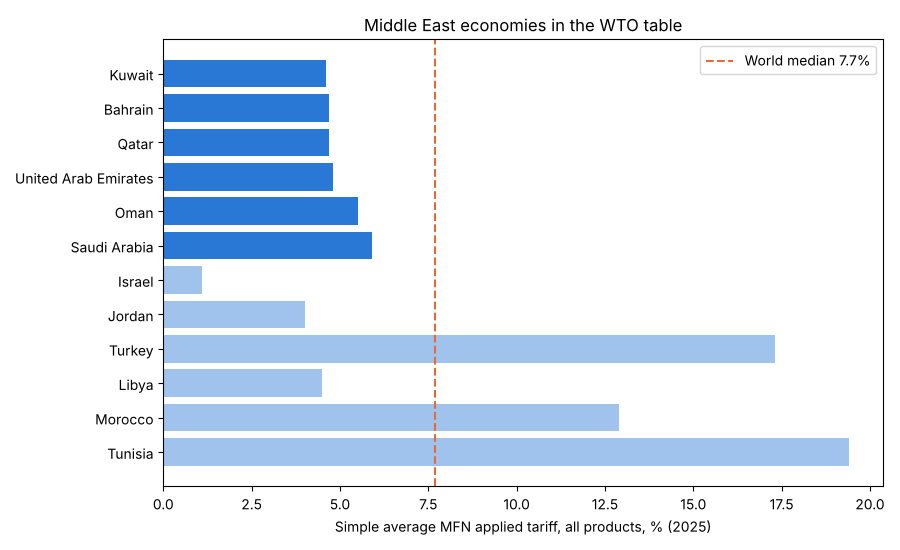

In [8]:
m = me[me.mfn_applied_avg.notna()]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(m.country, m.mfn_applied_avg, color=["#2a78d6" if s == "Gulf" else "#9fc3ec" for s in m.sub_region])
ax.axvline(world_median, color="#eb6834", ls="--", label=f"World median {world_median:.1f}%")
ax.invert_yaxis(); ax.set_xlabel("Simple average MFN applied tariff, all products, % (2025)"); ax.legend()
ax.set_title("Middle East economies in the WTO table")
plt.tight_layout(); plt.show()